# 02 — Exploratory data analysis
Statistical exploration of the cleaned hourly grid (`data/interim/hourly_air_pollution_clean.csv`) and the daily
targets. Figures are produced by `air_quality.eda.run_eda` and saved to `artifacts/figures/`; this notebook
re-computes the key statistics visibly and prints data-driven interpretations.

In [1]:
# --- Setup: locate the project root and import the package --------------------
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from air_quality.config import load_config, setup_logging
cfg = load_config(ROOT / "config.yaml"); setup_logging(cfg, "notebooks")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
FIG = cfg.path("figures_dir"); MET = cfg.path("metrics_dir")
print("Project root:", ROOT)

Project root: /Users/dannieey/Desktop/ML_final


In [2]:
if not cfg.path("features_csv").exists():
    raise FileNotFoundError("Run: python -m air_quality.cli preprocess")
from air_quality.preprocessing import load_clean
from air_quality.eda import run_eda, SEASONS
g = load_clean(cfg.path("clean_hourly_csv"), cfg.tz)
obs = g[g.is_observed].copy()
summary = run_eda(cfg)   # writes all EDA figures + eda_summary.json
print(f"Grid rows: {len(g)} | observed hours: {len(obs)} | missing hours: {(~g.is_observed).sum()}")

/Users/dannieey/Desktop/ML_final/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


2026-11-17 07:46:20 | INFO    | EDA figures written to /Users/dannieey/Desktop/ML_final/artifacts/figures


Grid rows: 43969 | observed hours: 43273 | missing hours: 696


## 1. Dataset overview and descriptive statistics (µg/m³)

In [3]:
desc = pd.read_csv(MET / "eda_descriptive_statistics.csv", index_col=0)
display(desc.round(2))

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max,skew,missing
pm2_5,43273.0,5.96,7.14,0.00,0.53,1.60,3.46,7.38,19.98,35.59,87.67,2.97,0
pm10,43272.0,7.64,10.16,0.00,0.63,1.86,4.14,9.24,26.18,50.49,224.98,4.03,1
no2,43271.0,8.68,9.31,0.04,0.26,3.13,5.83,10.88,27.08,45.24,104.19,2.68,2
co,43273.0,250.11,122.70,81.06,107.88,191.93,247.00,290.39,400.54,567.44,3952.03,10.69,0
o3,43272.0,55.18,25.14,0.00,8.85,38.27,56.51,72.96,94.41,108.72,246.05,-0.13,1
so2,43273.0,17.22,19.76,0.00,0.15,6.68,12.04,20.98,51.02,96.32,312.81,4.01,0
nh3,43273.0,0.33,0.46,0.00,0.00,0.06,0.18,0.42,1.22,2.28,11.65,3.78,0
no,43273.0,1.57,5.10,0.00,0.00,0.01,0.09,0.85,7.86,25.71,104.61,7.09,0
aqi,43273.0,1.61,0.65,1.00,1.00,1.00,2.00,2.00,3.00,4.00,5.00,0.98,0


## 2. Missing values and completeness over time

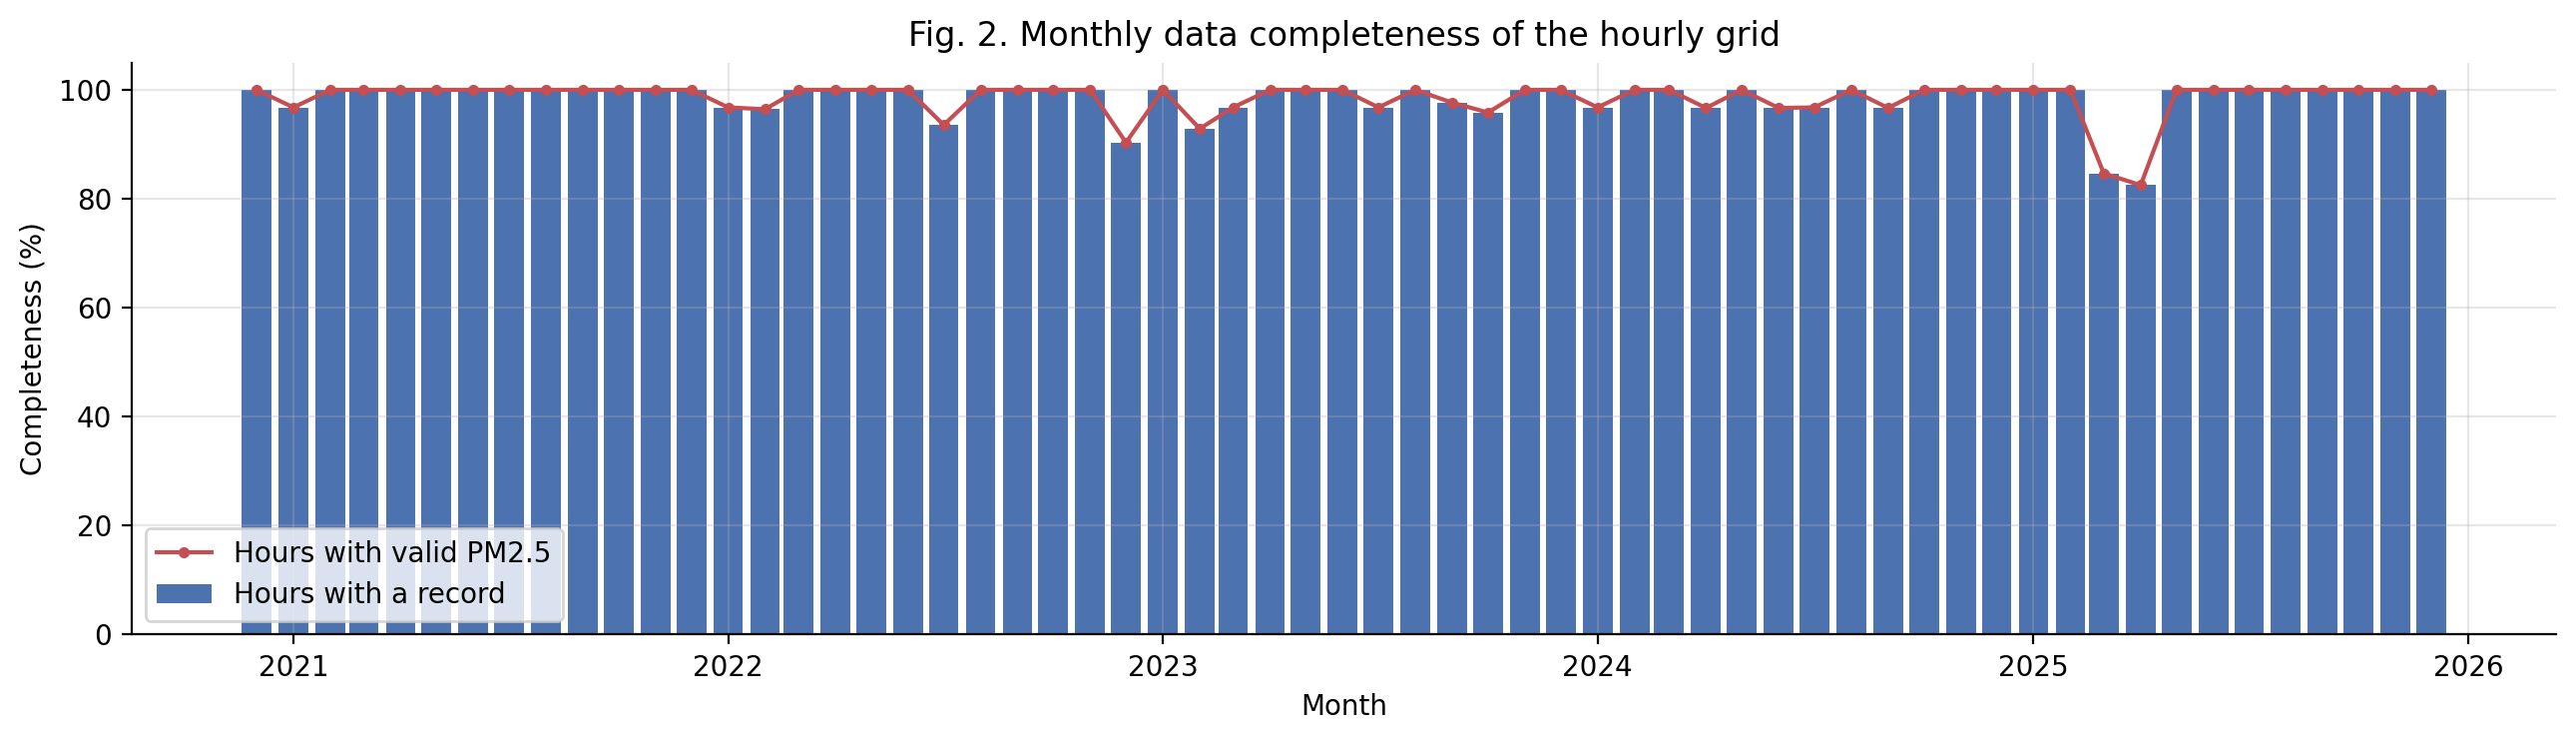

Months with <90% observed hours: 2 of 61; longest gap: 120 h; number of gaps: 20


In [4]:
display(Image(FIG / "02_missing_values_completeness.png"))
mc = pd.read_csv(MET / "eda_monthly_completeness.csv")
print(f"Months with <90% observed hours: {(mc.pct_hours_observed < 90).sum()} of {len(mc)}; "
      f"longest gap: {summary['gaps']['max_gap_hours']} h; number of gaps: {summary['gaps']['n_gaps']}")

## 3. Distributions of PM2.5, PM10 and other pollutants

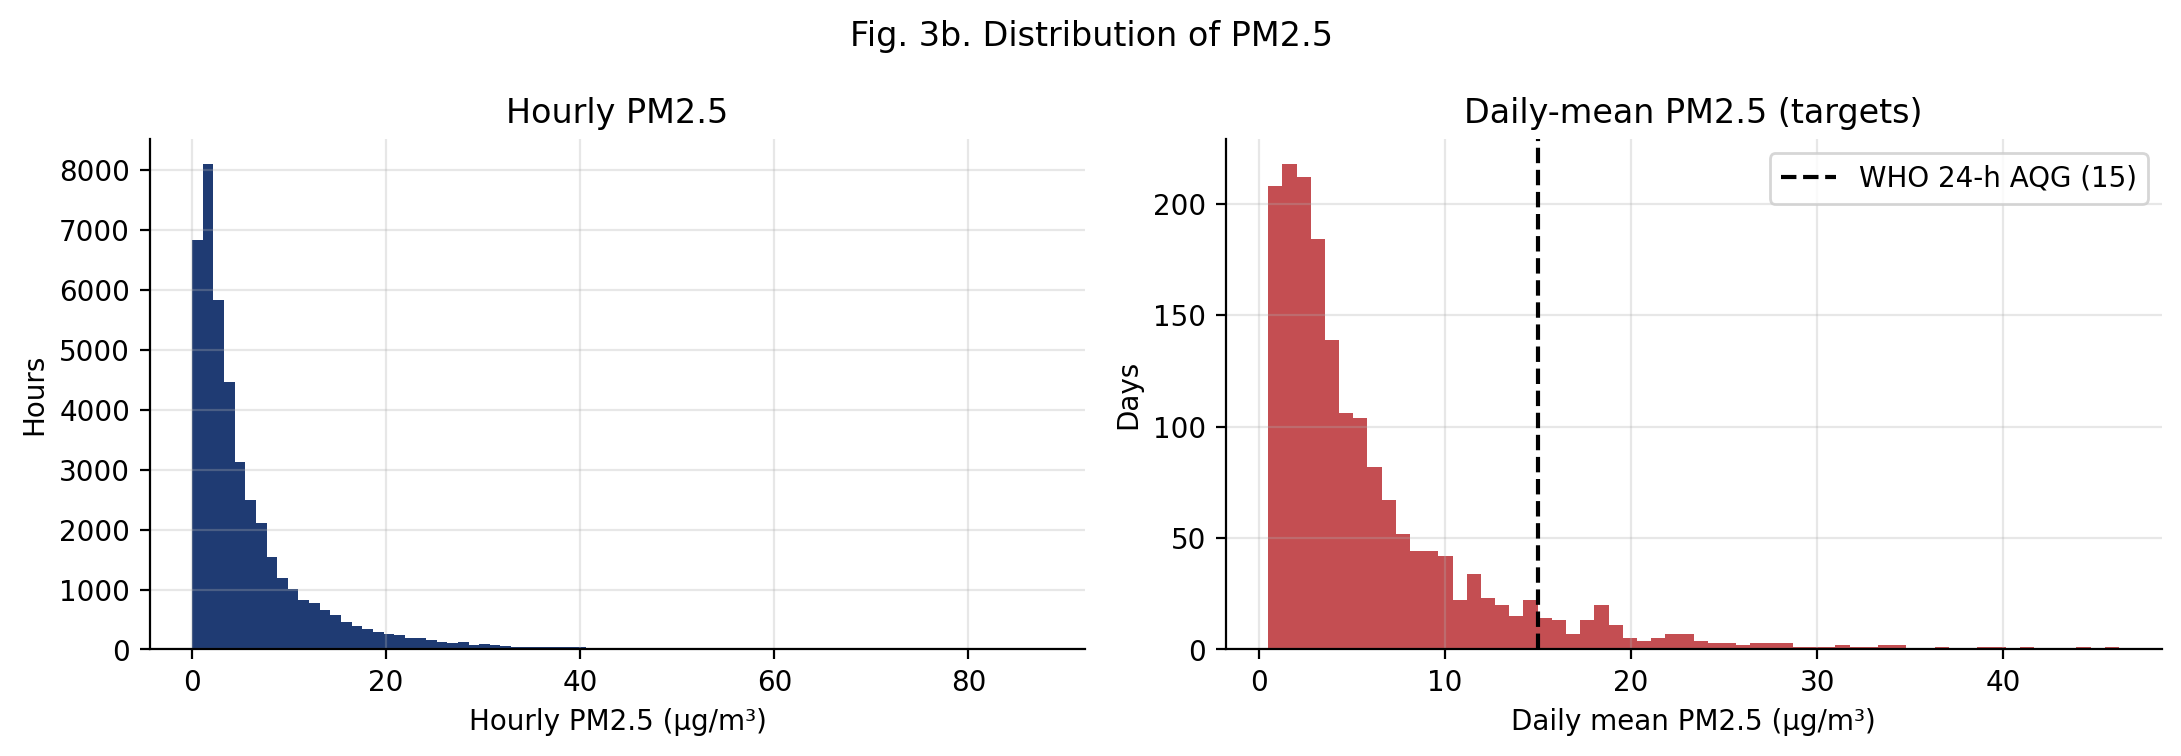

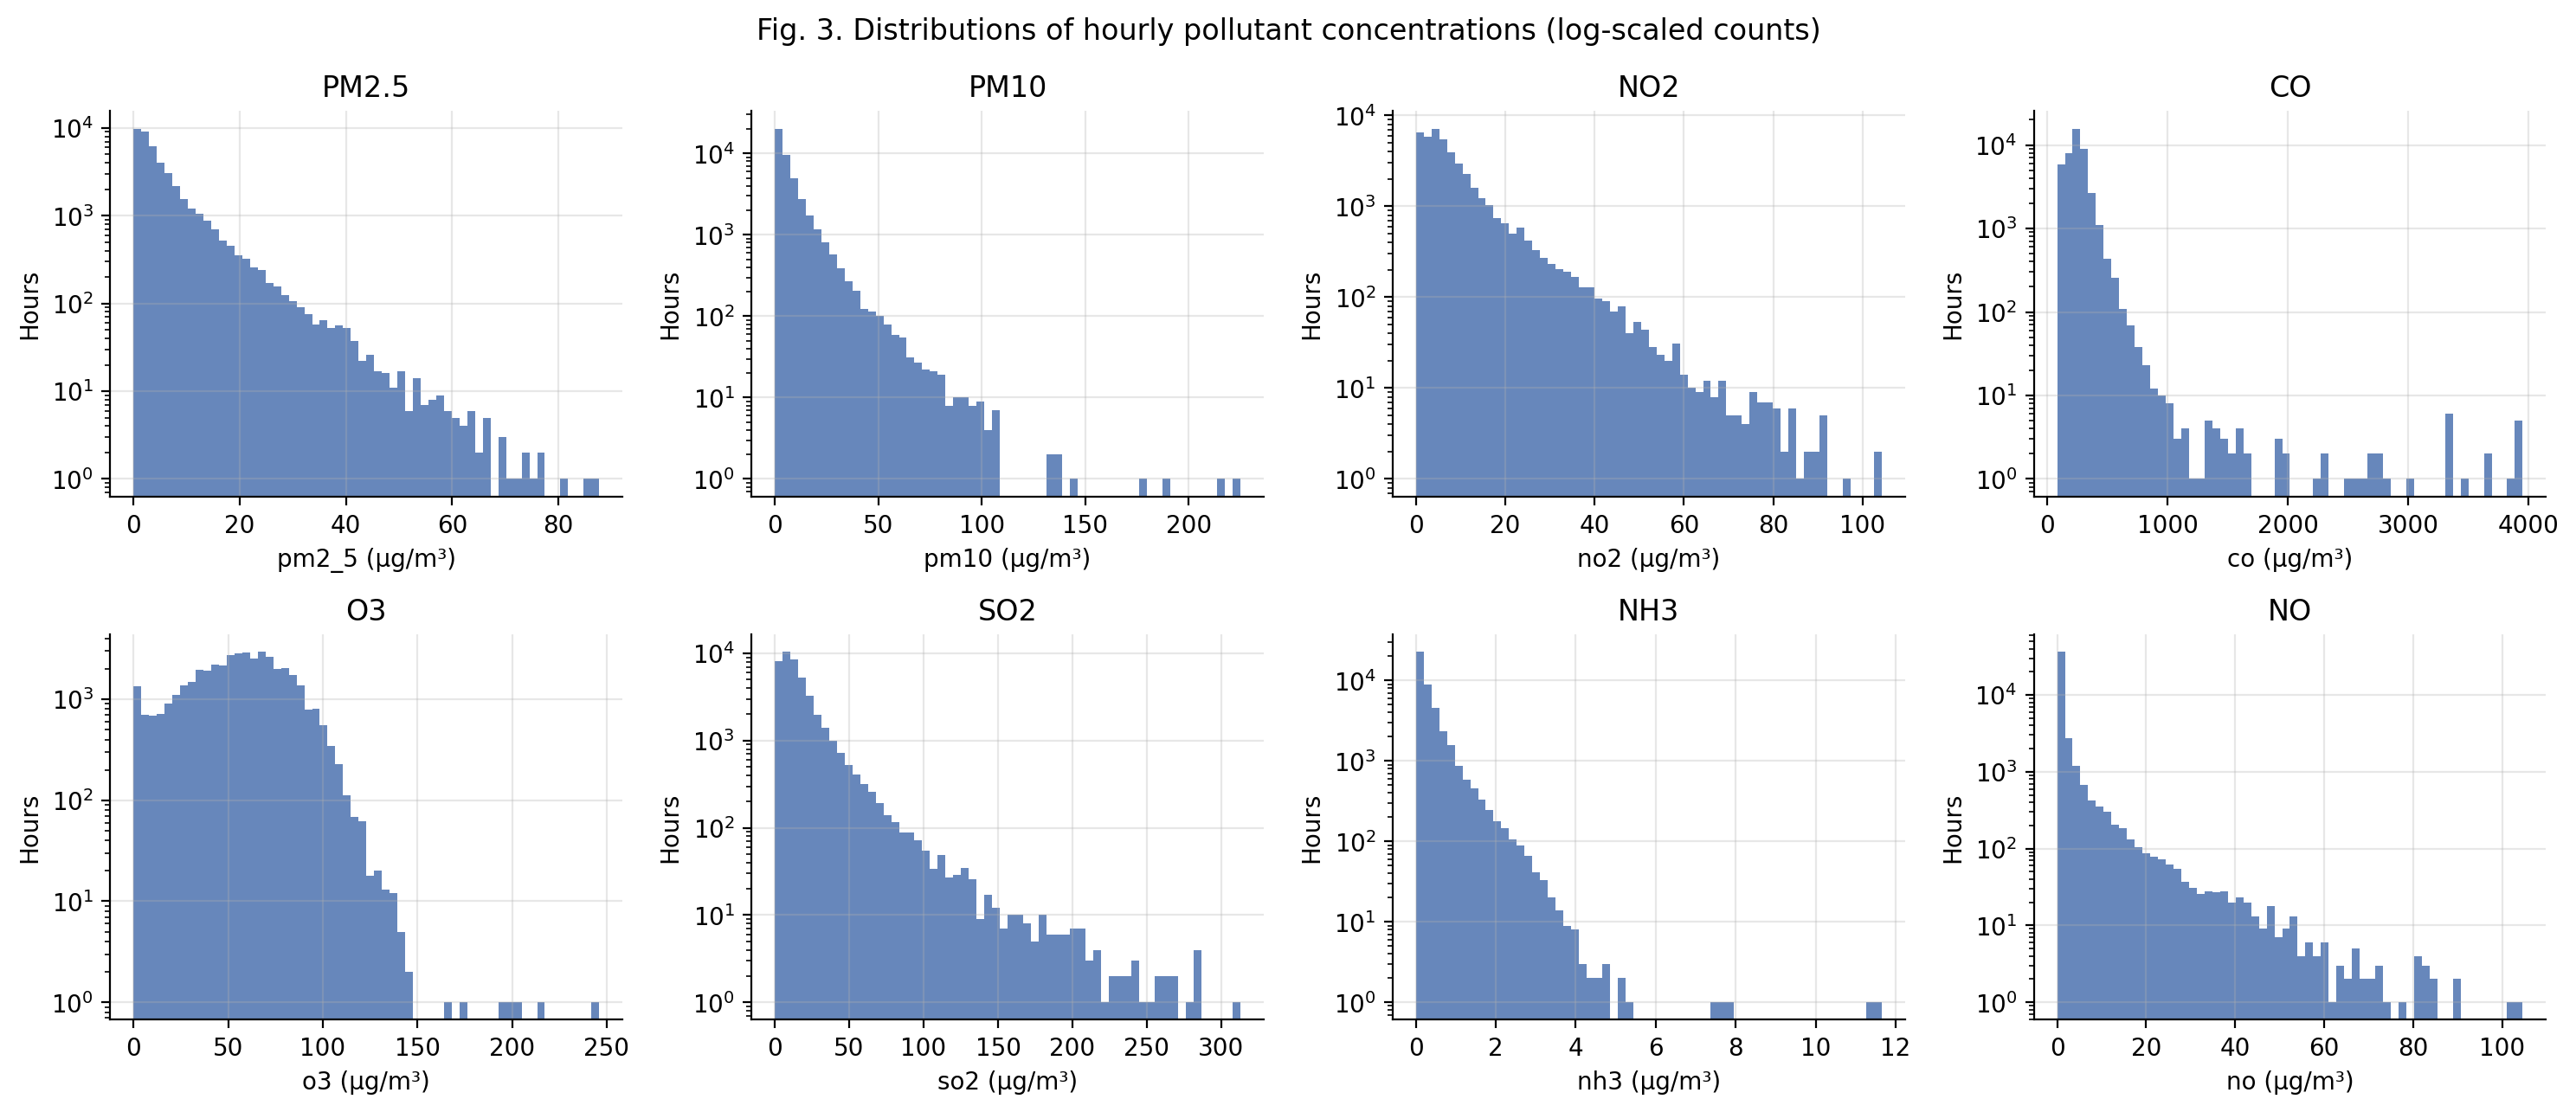

Hourly PM2.5 skewness = 2.97; median = 3.46, mean = 5.96 µg/m³ (mean > median indicates a right-skewed distribution).


In [5]:
display(Image(FIG / "03b_pm25_distribution.png")); display(Image(FIG / "03_pollutant_distributions.png"))
print(f"Hourly PM2.5 skewness = {obs.pm2_5.skew():.2f}; median = {obs.pm2_5.median():.2f}, mean = {obs.pm2_5.mean():.2f} µg/m³ "
      "(mean > median indicates a right-skewed distribution).")

## 4. Hourly and daily PM2.5 time series

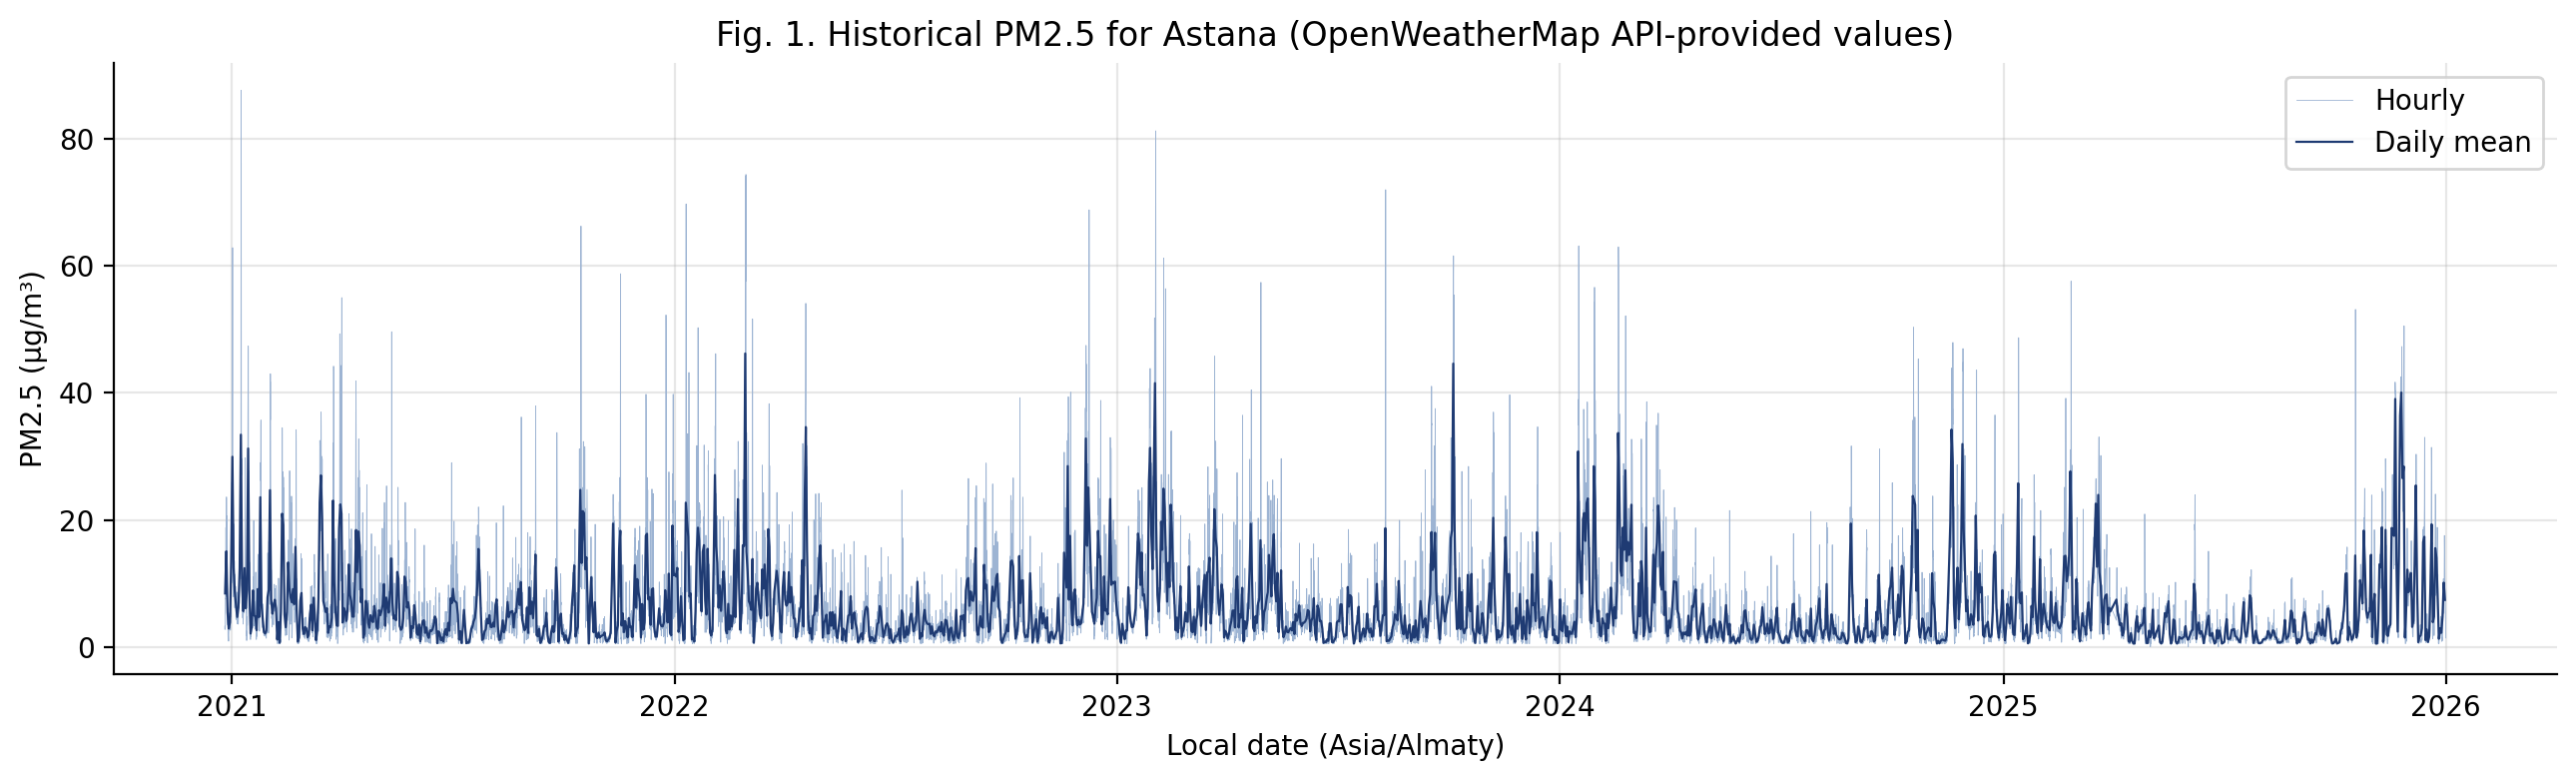

In [6]:
display(Image(FIG / "01_pm25_timeseries.png"))

## 5. Monthly, seasonal, day-of-week and hour-of-day patterns
Heating season is defined by convention as **15 October – 15 April** (documented in `config.yaml`; it approximates the municipal heating period and is an assumption, not a measured quantity).

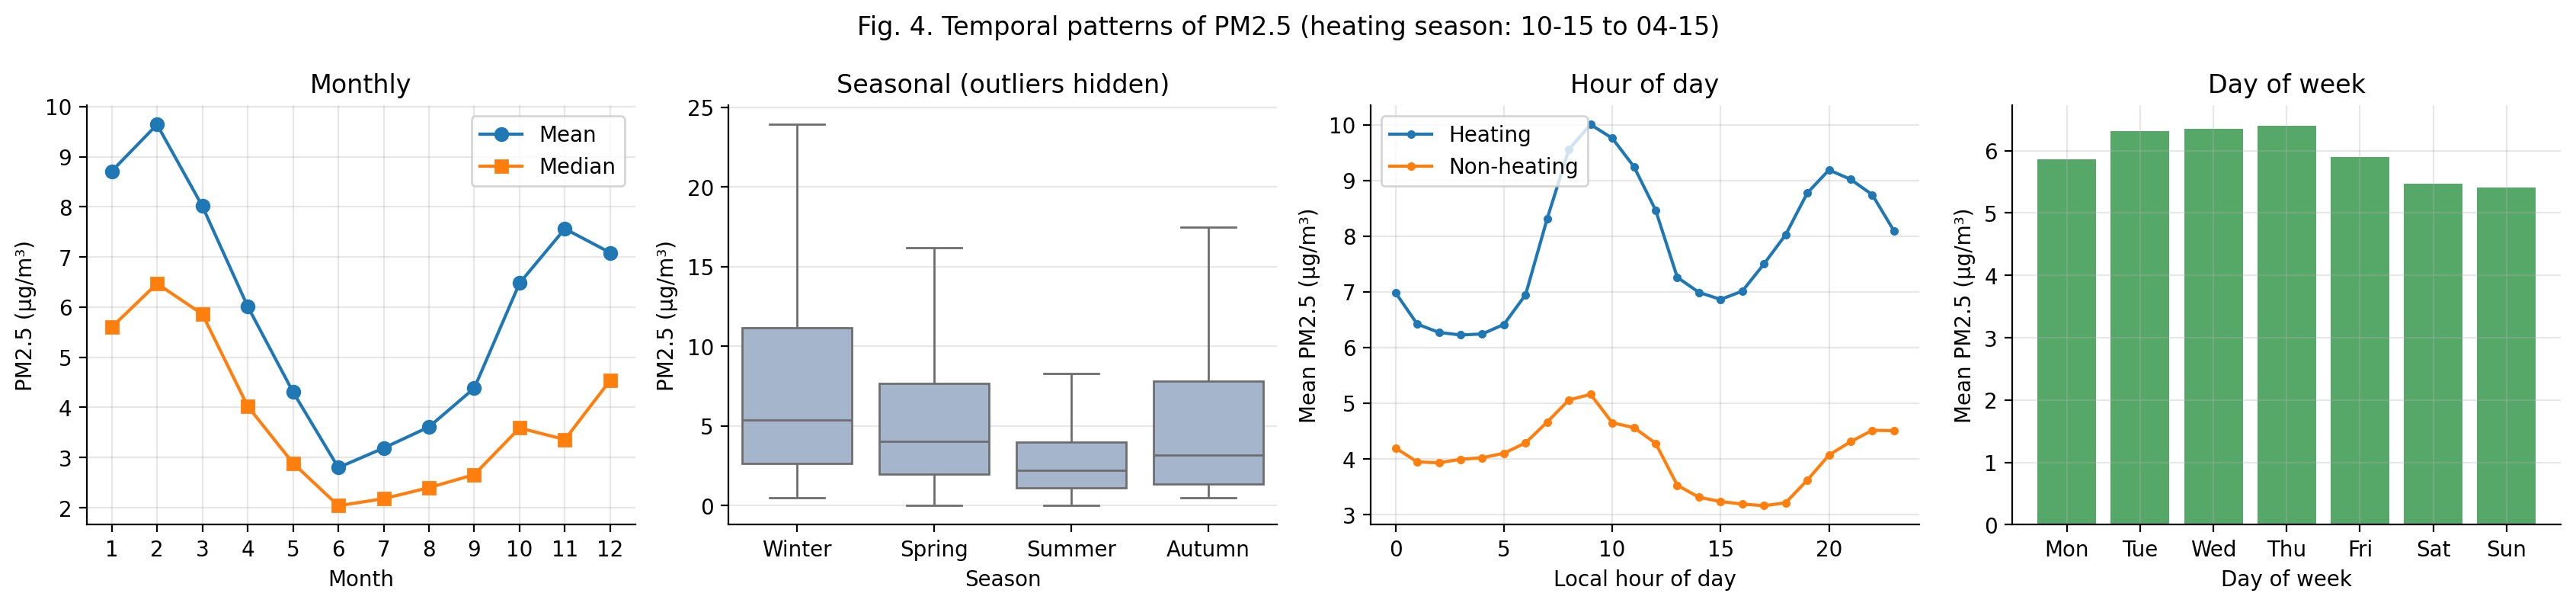

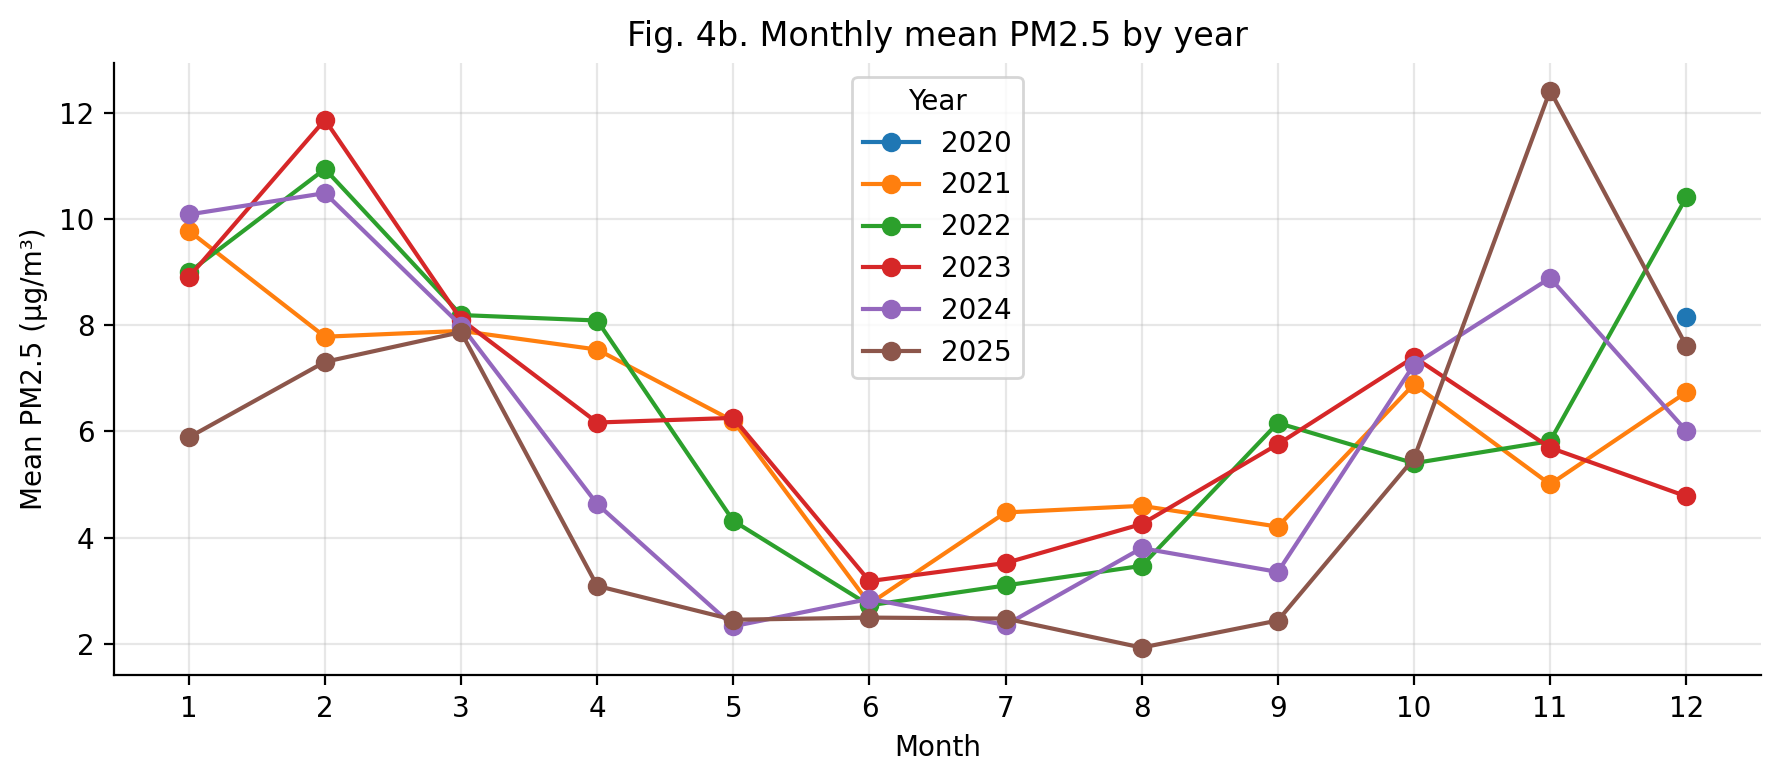

,mean PM2.5 (µg/m³)
Winter,8.424
Spring,6.090
Summer,3.205
Autumn,6.151


,mean,median,count
Heating,7.849,4.90,21655
Non-heating,4.063,2.54,21618


Interpretation: mean hourly PM2.5 in the heating season is 1.93 times the non-heating mean. This is an association in the API data; the cause is not established by this analysis.


In [7]:
display(Image(FIG / "04_seasonal_patterns.png")); display(Image(FIG / "04b_monthly_trend_by_year.png"))
sm = pd.Series(summary["seasonal_mean"]).reindex(["Winter", "Spring", "Summer", "Autumn"])
display(sm.rename("mean PM2.5 (µg/m³)").to_frame())
hm = pd.DataFrame(summary["heating_mean"])
display(hm)
ratio = hm.loc["Heating", "mean"] / hm.loc["Non-heating", "mean"]
print(f"Interpretation: mean hourly PM2.5 in the heating season is {ratio:.2f} times the non-heating mean. "
      "This is an association in the API data; the cause is not established by this analysis.")

## 6. Correlations and PM2.5 versus other pollutants

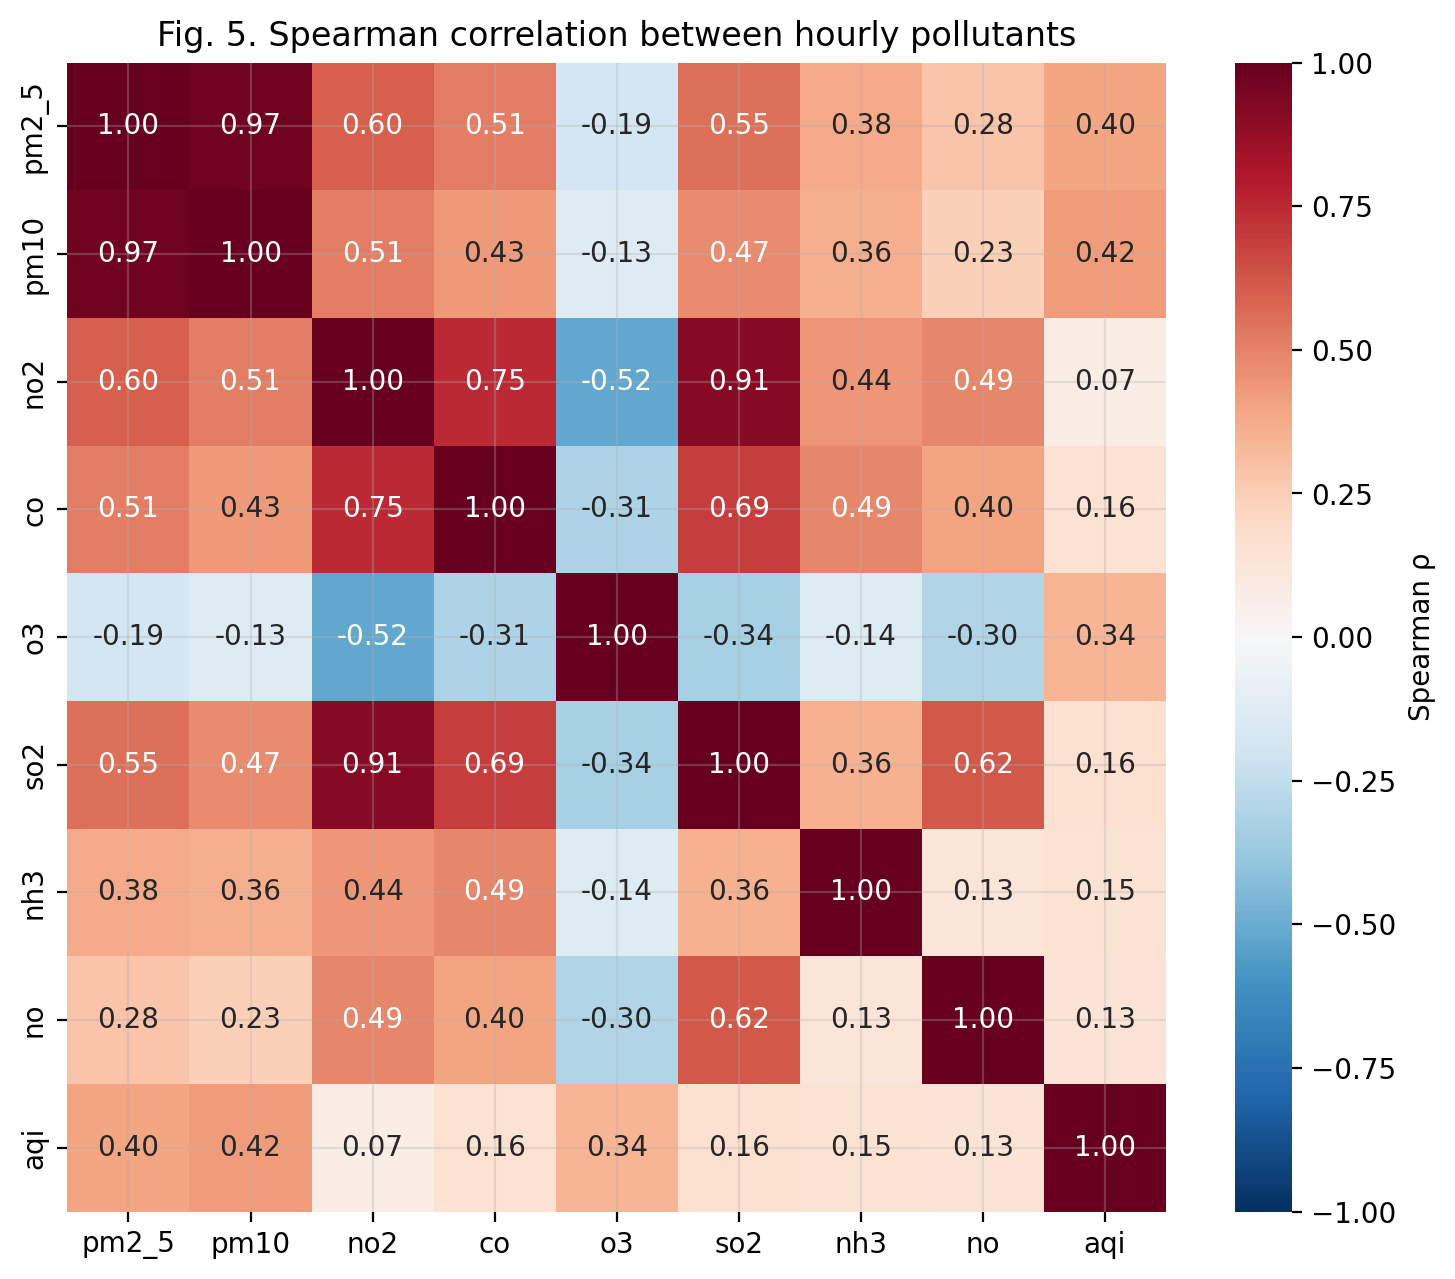

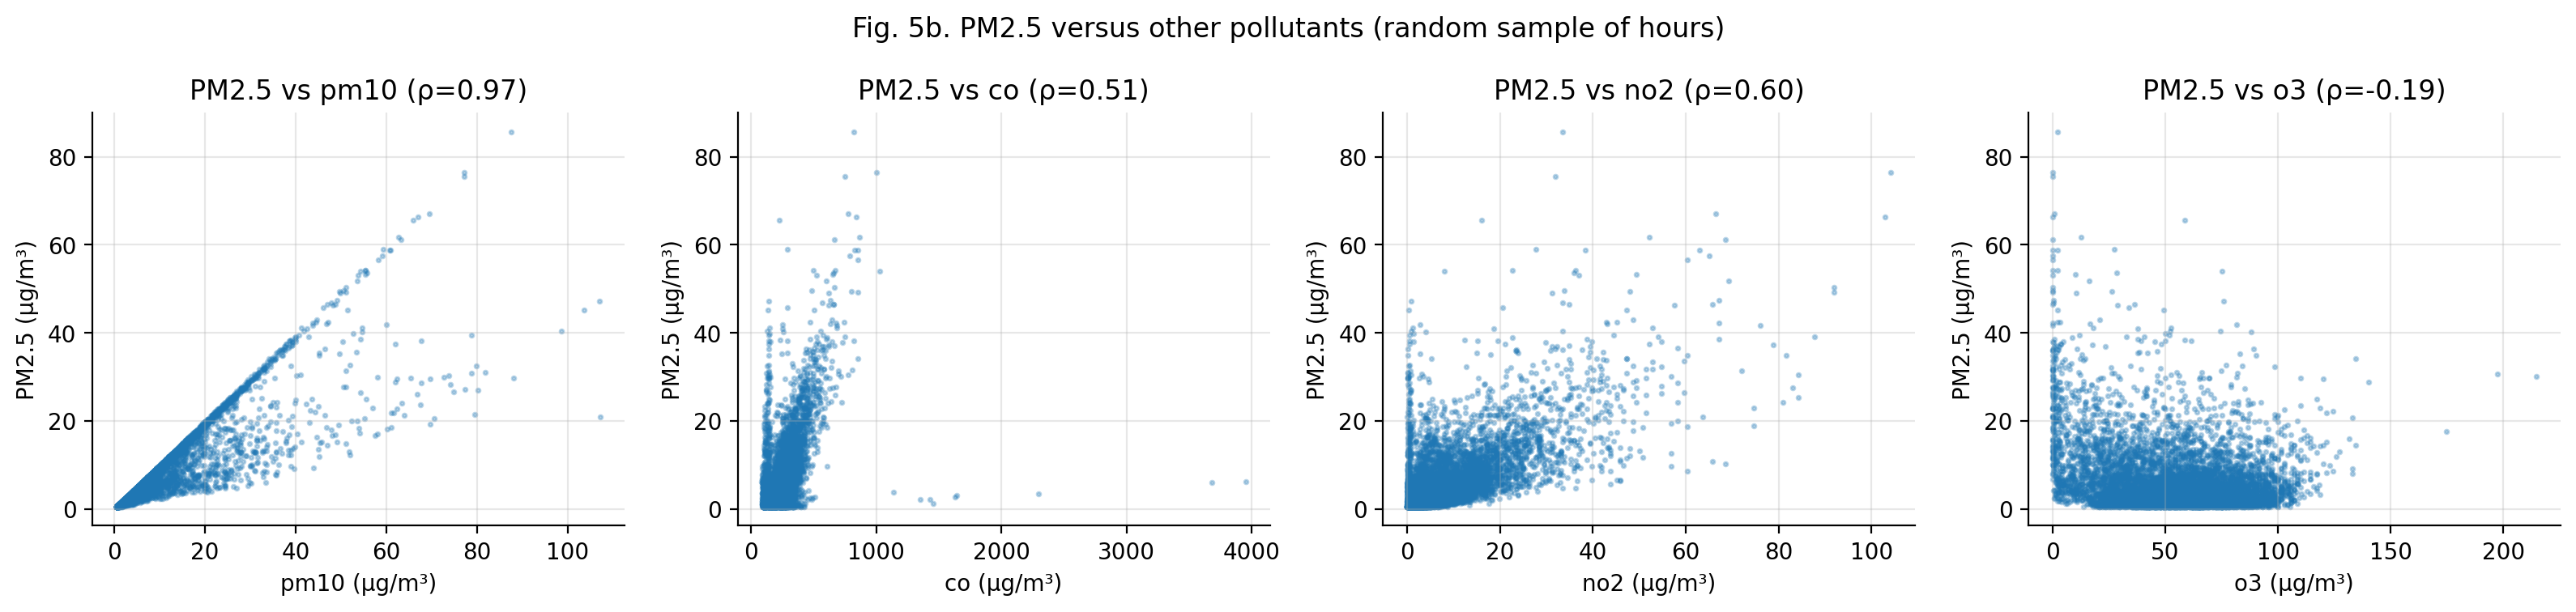

,Spearman rho with PM2.5
pm10,0.972
no2,0.596
so2,0.551
co,0.513
aqi,0.397
nh3,0.380
no,0.284
o3,-0.185


In [8]:
display(Image(FIG / "05_correlation_heatmap.png")); display(Image(FIG / "05b_pm25_vs_pollutants.png"))
c = pd.read_csv(MET / "eda_spearman_correlation.csv", index_col=0)["pm2_5"].drop("pm2_5").sort_values(key=abs, ascending=False)
display(c.rename("Spearman rho with PM2.5").to_frame().round(3))

## 7. Outliers and extreme pollution
Extreme hours are inspected statistically and **retained** (high-pollution episodes are exactly what a forecaster must handle).

In [9]:
print(json.dumps(summary["extremes"], indent=2))

{
  "hourly_q99": 35.588399999999965,
  "n_hours_above_q99": 433,
  "share_in_heating_season_pct": 88.91454965357968,
  "n_flagged_robust_z": 0,
  "daily_days_above_who_15": 143,
  "n_daily_targets": 1782
}


## 8. Autocorrelation, trend and stationarity

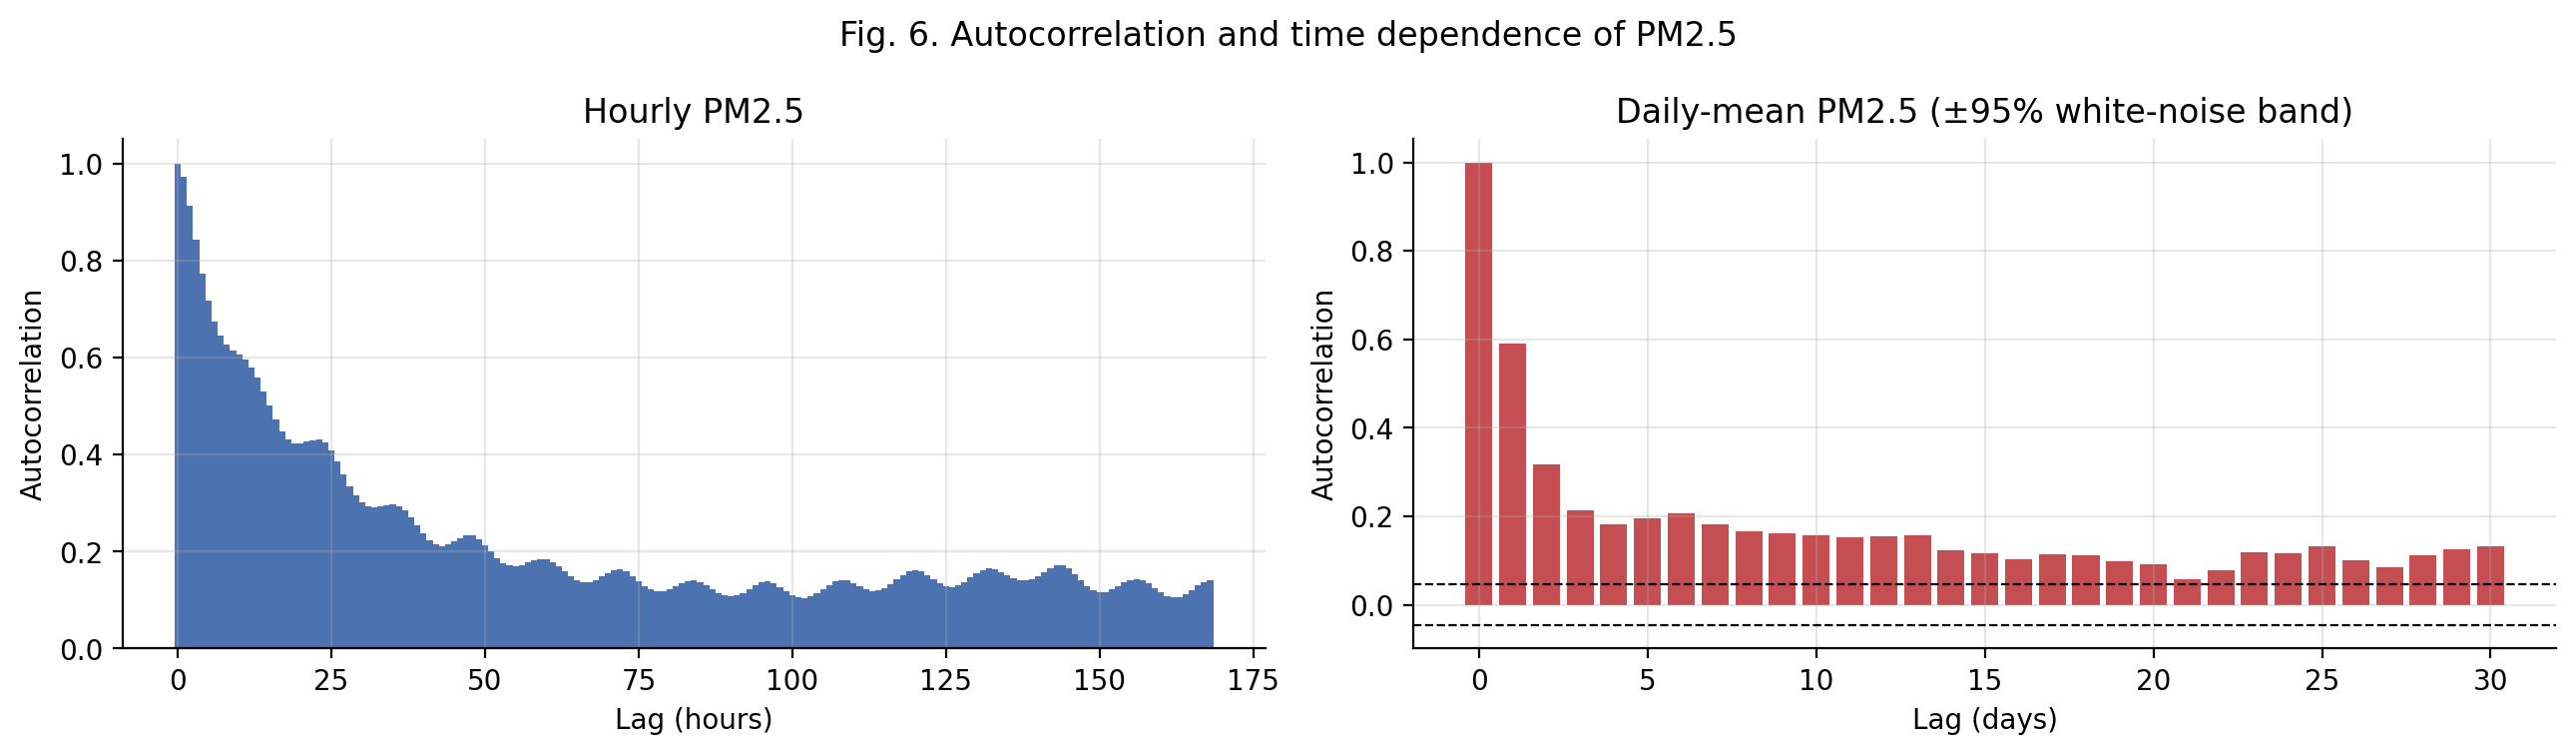

Hourly ACF: {'1': 0.9734, '6': 0.6738, '12': 0.5802, '24': 0.4253, '48': 0.233, '72': 0.1632, '168': 0.1412}
Daily ACF: {'1': 0.591, '2': 0.3164, '3': 0.2134, '7': 0.1827, '14': 0.1245, '30': 0.1321}
ADF (daily): {'statistic': -7.970351521497177, 'p_value': 2.7920745307828673e-12, 'n': 1782, 'note': 'ADF on daily means with gaps dropped (approximate)'}
Interpretation: the lag-1 daily autocorrelation is 0.59, which motivates lagged and rolling features and makes persistence a strong baseline.


In [10]:
display(Image(FIG / "06_autocorrelation.png"))
print("Hourly ACF:", summary["acf_hourly"]); print("Daily ACF:", summary["acf_daily"]); print("ADF (daily):", summary["adf_daily"])
print(f"Interpretation: the lag-1 daily autocorrelation is {summary['acf_daily']['1']:.2f}, which motivates lagged and rolling "
      "features and makes persistence a strong baseline.")

## 9. Train / validation / test split and distribution shift

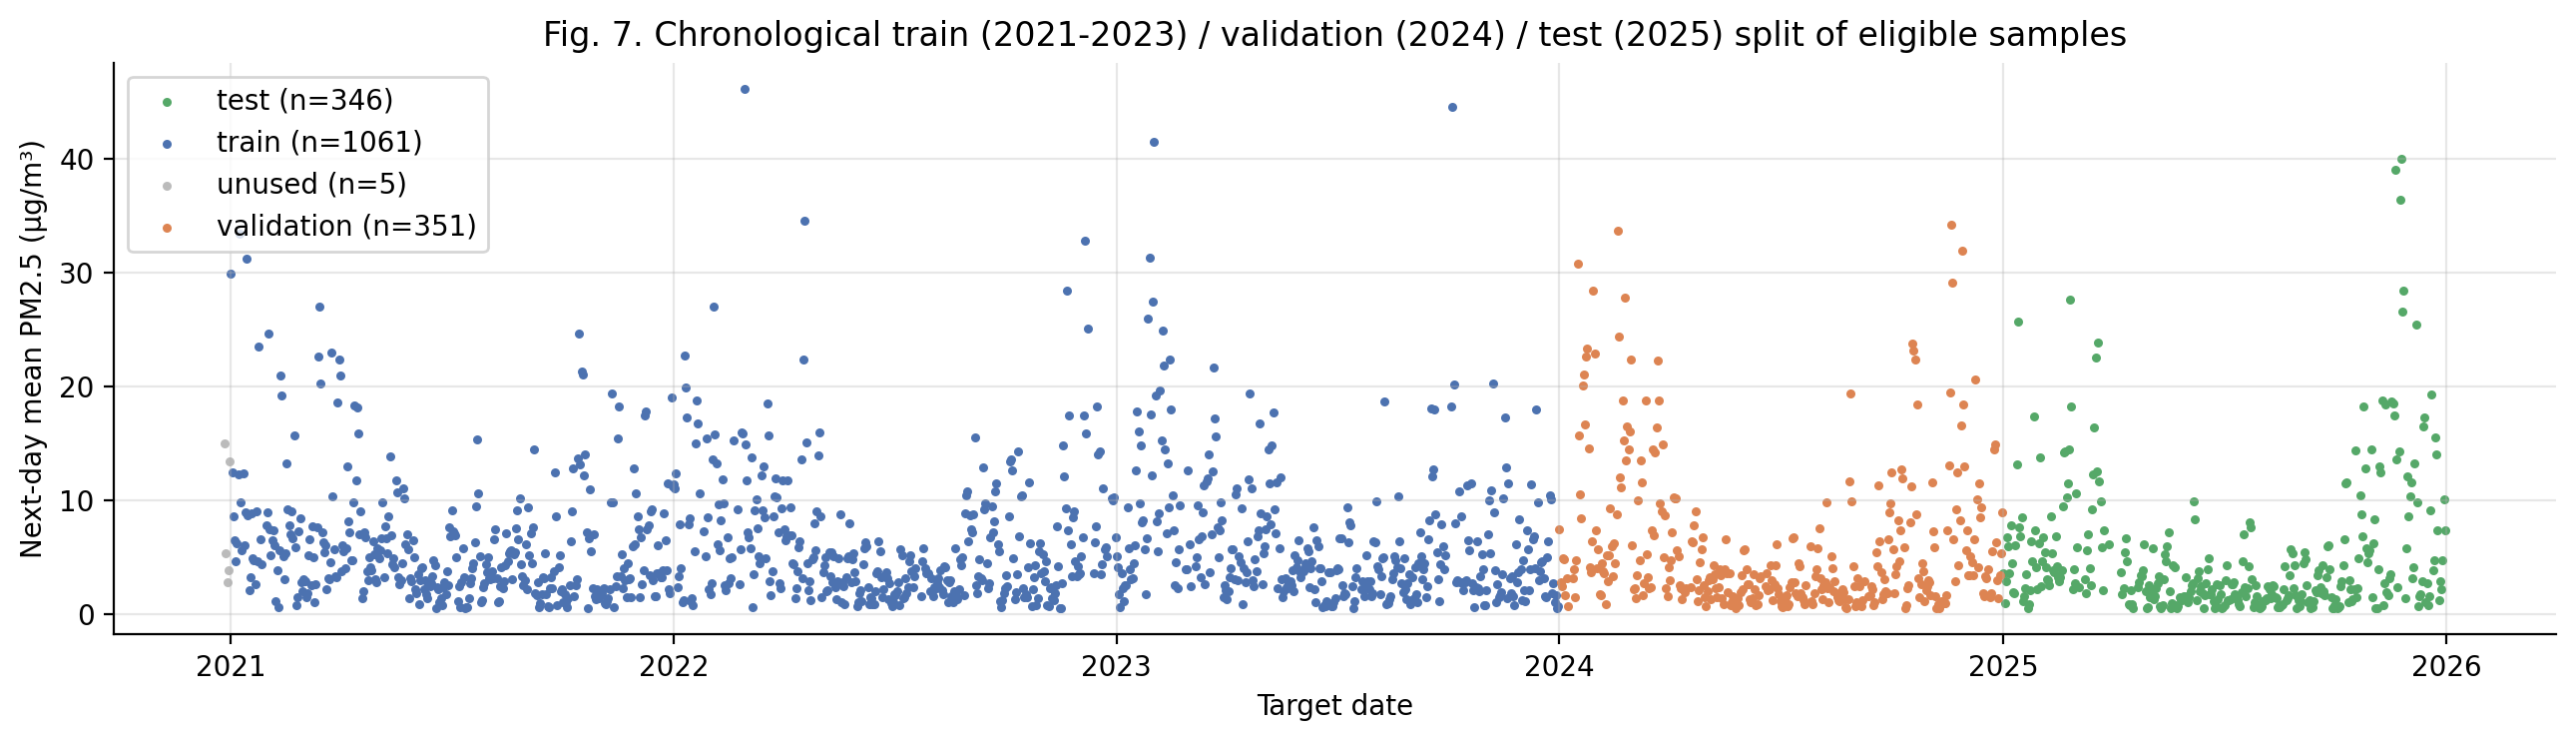

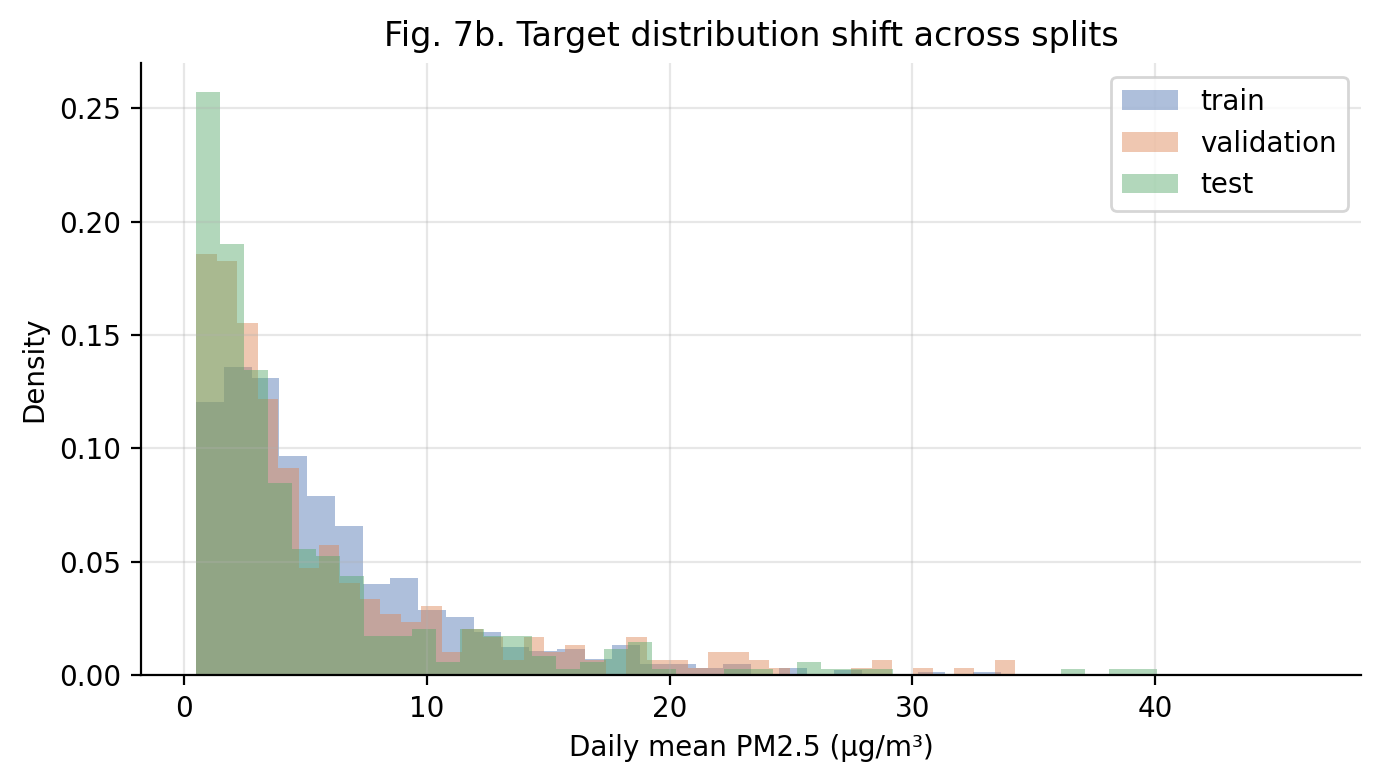

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,346.0,5.11,6.09,0.50,1.48,2.76,6.02,40.06
train,1061.0,6.24,5.72,0.50,2.46,4.47,7.96,46.21
unused,5.0,8.11,5.69,2.86,3.83,5.39,13.42,15.04
validation,351.0,5.92,6.38,0.50,1.82,3.42,7.35,34.23


Kolmogorov–Smirnov train vs other splits: {'validation': {'statistic': 0.1302888475367269, 'p_value': 0.00022778048686028062}, 'test': {'statistic': 0.21630537229029217, 'p_value': 3.440402360628792e-11}}


In [11]:
display(Image(FIG / "07_split_timeline.png")); display(Image(FIG / "07b_split_distribution_shift.png"))
display(pd.read_csv(MET / "eda_split_distribution_shift.csv", index_col=0).round(2))
print("Kolmogorov–Smirnov train vs other splits:", summary["ks_train_vs"])